# LipScribe mouth-crop pipeline

This notebook validates the repository implementation in `lipscribe/preprocessing/crop.py`. It:

1. mounts or locates the persistent project directory;
2. installs the MediaPipe/OpenCV runtime;
3. verifies the Face Landmarker model and corpus clips;
4. runs the stabilized 96×96 grayscale crop pipeline;
5. saves a five-clip contact sheet;
6. validates an artificially blanked clip, including interpolated boxes and invalid masks; and
7. saves crop arrays and metadata without overwriting source videos.

The notebook does **not** redefine or overwrite `crop.py` or `tests/test_crop.py`.

In [1]:
from pathlib import Path
import os
import sys

# Colab: mount Drive. Local Jupyter: this cell simply skips mounting.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# This notebook keeps the existing relative-path convention.
# Run it from the experiments/ directory.
PROJECT_ROOT = Path("../").resolve()
os.chdir(PROJECT_ROOT / "experiments")

# Support both the repository layout and the older src/lipscribe layout.
SOURCE_ROOT = PROJECT_ROOT / "src" if (PROJECT_ROOT / "src" / "lipscribe").is_dir() else PROJECT_ROOT
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

DATA_DIR = Path("../data/mouth_crop_clips")
MODEL_DIR = Path("../models")
ARTIFACT_DIR = Path("../docs/mouth_crop")
EXPERIMENT_DIR = Path(".")
CROPS_DIR = Path("mouth_crops")
METADATA_DIR = Path("mouth_crop_results_metadata")

for directory in (MODEL_DIR, ARTIFACT_DIR, CROPS_DIR, METADATA_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Source root:", SOURCE_ROOT)
print("Working directory:", Path.cwd())

Project root: /home/kingcole/Documents/uniAssignments/year_3_sem_1/cv_group_4
Source root: /home/kingcole/Documents/uniAssignments/year_3_sem_1/cv_group_4
Working directory: /home/kingcole/Documents/uniAssignments/year_3_sem_1/cv_group_4/experiments


In [2]:
# Install the runtime used by the crop implementation.
# Re-running this cell is safe.
%pip install -q mediapipe==0.10.35 opencv-python-headless numpy matplotlib pytest


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

from lipscribe.preprocessing.crop import (
    MAX_INVALID_FRACTION,
    crop_video,
    get_lip_indices,
)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("Lip landmark count:", len(get_lip_indices()))
print("Invalid-frame threshold:", MAX_INVALID_FRACTION)

Python: 3.14.4
NumPy: 2.3.5
OpenCV: 5.0.0
MediaPipe: 0.10.35
Lip landmark count: 40
Invalid-frame threshold: 0.1


In [4]:
import urllib.request

FACE_LANDMARKER_MODEL = MODEL_DIR / "face_landmarker.task"
MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)

if not FACE_LANDMARKER_MODEL.exists():
    print("Downloading Face Landmarker model...")
    urllib.request.urlretrieve(MODEL_URL, FACE_LANDMARKER_MODEL)

assert FACE_LANDMARKER_MODEL.exists()
assert FACE_LANDMARKER_MODEL.stat().st_size > 1_000_000
print("Model:", FACE_LANDMARKER_MODEL)
print("Model size MB:", round(FACE_LANDMARKER_MODEL.stat().st_size / 2**20, 2))

Model: ../models/face_landmarker.task
Model size MB: 3.58


In [5]:
# Keep the original five-clip regression set separate from optional validation clips.
BASELINE_CLIPS = [
    DATA_DIR / f"clip_{index}.mp4"
    for index in range(1, 6)
]
BLANKED_CLIP = DATA_DIR / "clip_6_blank.mp4"

missing = [path for path in BASELINE_CLIPS if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing baseline clips: {missing}")

print("Baseline clips:")
for path in BASELINE_CLIPS:
    print(" -", path.name)
print("Blanked validation clip:", BLANKED_CLIP, "exists=", BLANKED_CLIP.exists())

Baseline clips:
 - clip_1.mp4
 - clip_2.mp4
 - clip_3.mp4
 - clip_4.mp4
 - clip_5.mp4
Blanked validation clip: ../data/mouth_crop_clips/clip_6_blank.mp4 exists= True


In [6]:
# Run the pipeline on one baseline clip.
test_clip = BASELINE_CLIPS[0]
result = crop_video(
    video_path=test_clip,
    model_path=FACE_LANDMARKER_MODEL,
)

print("Video:", test_clip.name)
print("Crops:", result.crops.shape, result.crops.dtype)
print("Validity:", result.valid.shape, result.valid.dtype)
print("Valid frames:", int(result.valid.sum()), "/", len(result.valid))
print("Invalid fraction:", result.invalid_fraction)
print("Exclude utterance:", result.exclude_utterance)

assert result.crops.ndim == 3
assert result.crops.shape[1:] == (96, 96)
assert result.crops.dtype == np.uint8
assert len(result.crops) == len(result.valid) == len(result.frame_indices)

W0000 00:00:1793248463.786276  265373 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248464.721044  265373 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248464.762767  265383 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793248464.808706  265375 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248464.967888  265376 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: clip_1.mp4
Crops: (107, 96, 96) uint8
Validity: (107,) bool
Valid frames: 107 / 107
Invalid fraction: 0.0
Exclude utterance: False


Processing clip_1.mp4...


W0000 00:00:1793248482.431280  265409 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248482.445408  265409 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248482.507016  265417 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
W0000 00:00:1793248482.544340  265413 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248482.676419  265414 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  frames=107, valid=107/107, shape=(107, 96, 96), dtype=uint8
Processing clip_2.mp4...


W0000 00:00:1793248494.782996  265435 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248494.793219  265435 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248494.798936  265443 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
W0000 00:00:1793248494.803229  265440 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248494.840511  265437 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  frames=75, valid=75/75, shape=(75, 96, 96), dtype=uint8
Processing clip_3.mp4...


...

  frames=207, valid=207/207, shape=(207, 96, 96), dtype=uint8
Processing clip_4.mp4...


W0000 00:00:1793248520.686655  265494 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248520.711543  265494 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248520.717970  265502 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
W0000 00:00:1793248520.722926  265499 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248520.767374  265498 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  frames=97, valid=97/97, shape=(97, 96, 96), dtype=uint8
Processing clip_5.mp4...


W0000 00:00:1793248531.295910  265514 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248531.305888  265514 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248531.310481  265522 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
W0000 00:00:1793248531.314207  265518 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248531.347115  265517 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  frames=53, valid=53/53, shape=(53, 96, 96), dtype=uint8


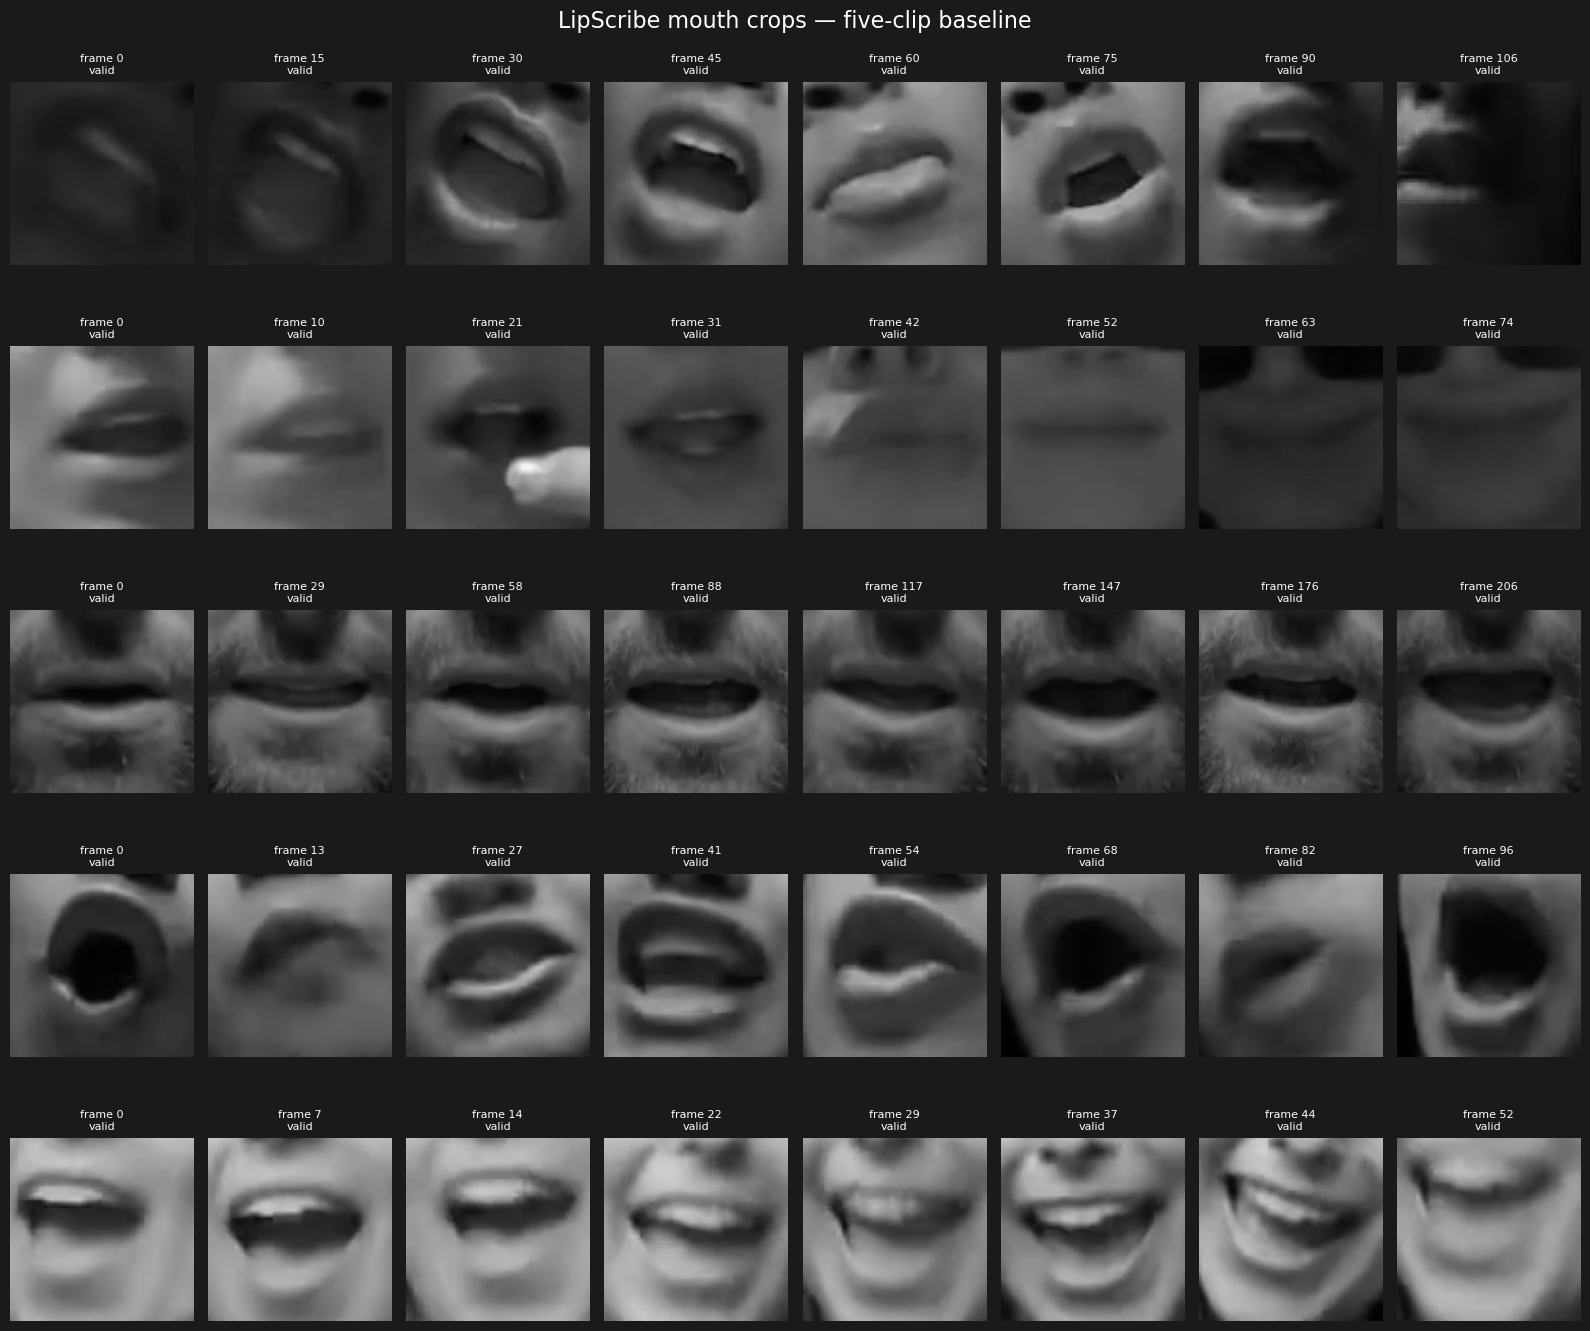

Saved: ../docs/mouth_crop/lip_crops_all_clips_v002.png


In [7]:
# Contact sheet for the five baseline clips.
all_results = {}
for clip_path in BASELINE_CLIPS:
    print(f"Processing {clip_path.name}...")
    clip_result = crop_video(
        video_path=clip_path,
        model_path=FACE_LANDMARKER_MODEL,
    )
    all_results[clip_path.name] = clip_result
    print(
        f"  frames={len(clip_result.crops)}, "
        f"valid={int(clip_result.valid.sum())}/{len(clip_result.valid)}, "
        f"shape={clip_result.crops.shape}, dtype={clip_result.crops.dtype}"
    )

columns = 8
rows = len(BASELINE_CLIPS)
fig, axes = plt.subplots(rows, columns, figsize=(16, 2.8 * rows), squeeze=False)

for row, clip_path in enumerate(BASELINE_CLIPS):
    clip_result = all_results[clip_path.name]
    positions = np.linspace(0, len(clip_result.crops) - 1, columns, dtype=int)
    for column, position in enumerate(positions):
        axis = axes[row, column]
        axis.imshow(clip_result.crops[position], cmap="gray", vmin=0, vmax=255)
        status = "valid" if clip_result.valid[position] else "INVALID / interpolated"
        axis.set_title(f"frame {clip_result.frame_indices[position]}\n{status}", fontsize=8)
        axis.axis("off")
    axes[row, 0].set_ylabel(clip_path.name, fontsize=10, rotation=90, labelpad=22)

fig.suptitle("LipScribe mouth crops — five-clip baseline", fontsize=16)
plt.tight_layout()
contact_sheet_path = ARTIFACT_DIR / "lip_crops_all_clips_v002.png"
fig.savefig(contact_sheet_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", contact_sheet_path)

W0000 00:00:1793248550.466211  265559 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1793248550.499271  265559 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793248550.506282  265567 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) HD Graphics 620 (KBL GT2)
W0000 00:00:1793248550.512938  265561 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793248550.576030  265563 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Clip: clip_6_blank.mp4
Crops: (107, 96, 96) uint8
Valid frames: 97 / 107
Invalid frame indices: [40, 41, 42, 43, 44, 45, 46, 47, 48, 49]
Invalid fraction: 0.09345794392523364
Exclude utterance: False


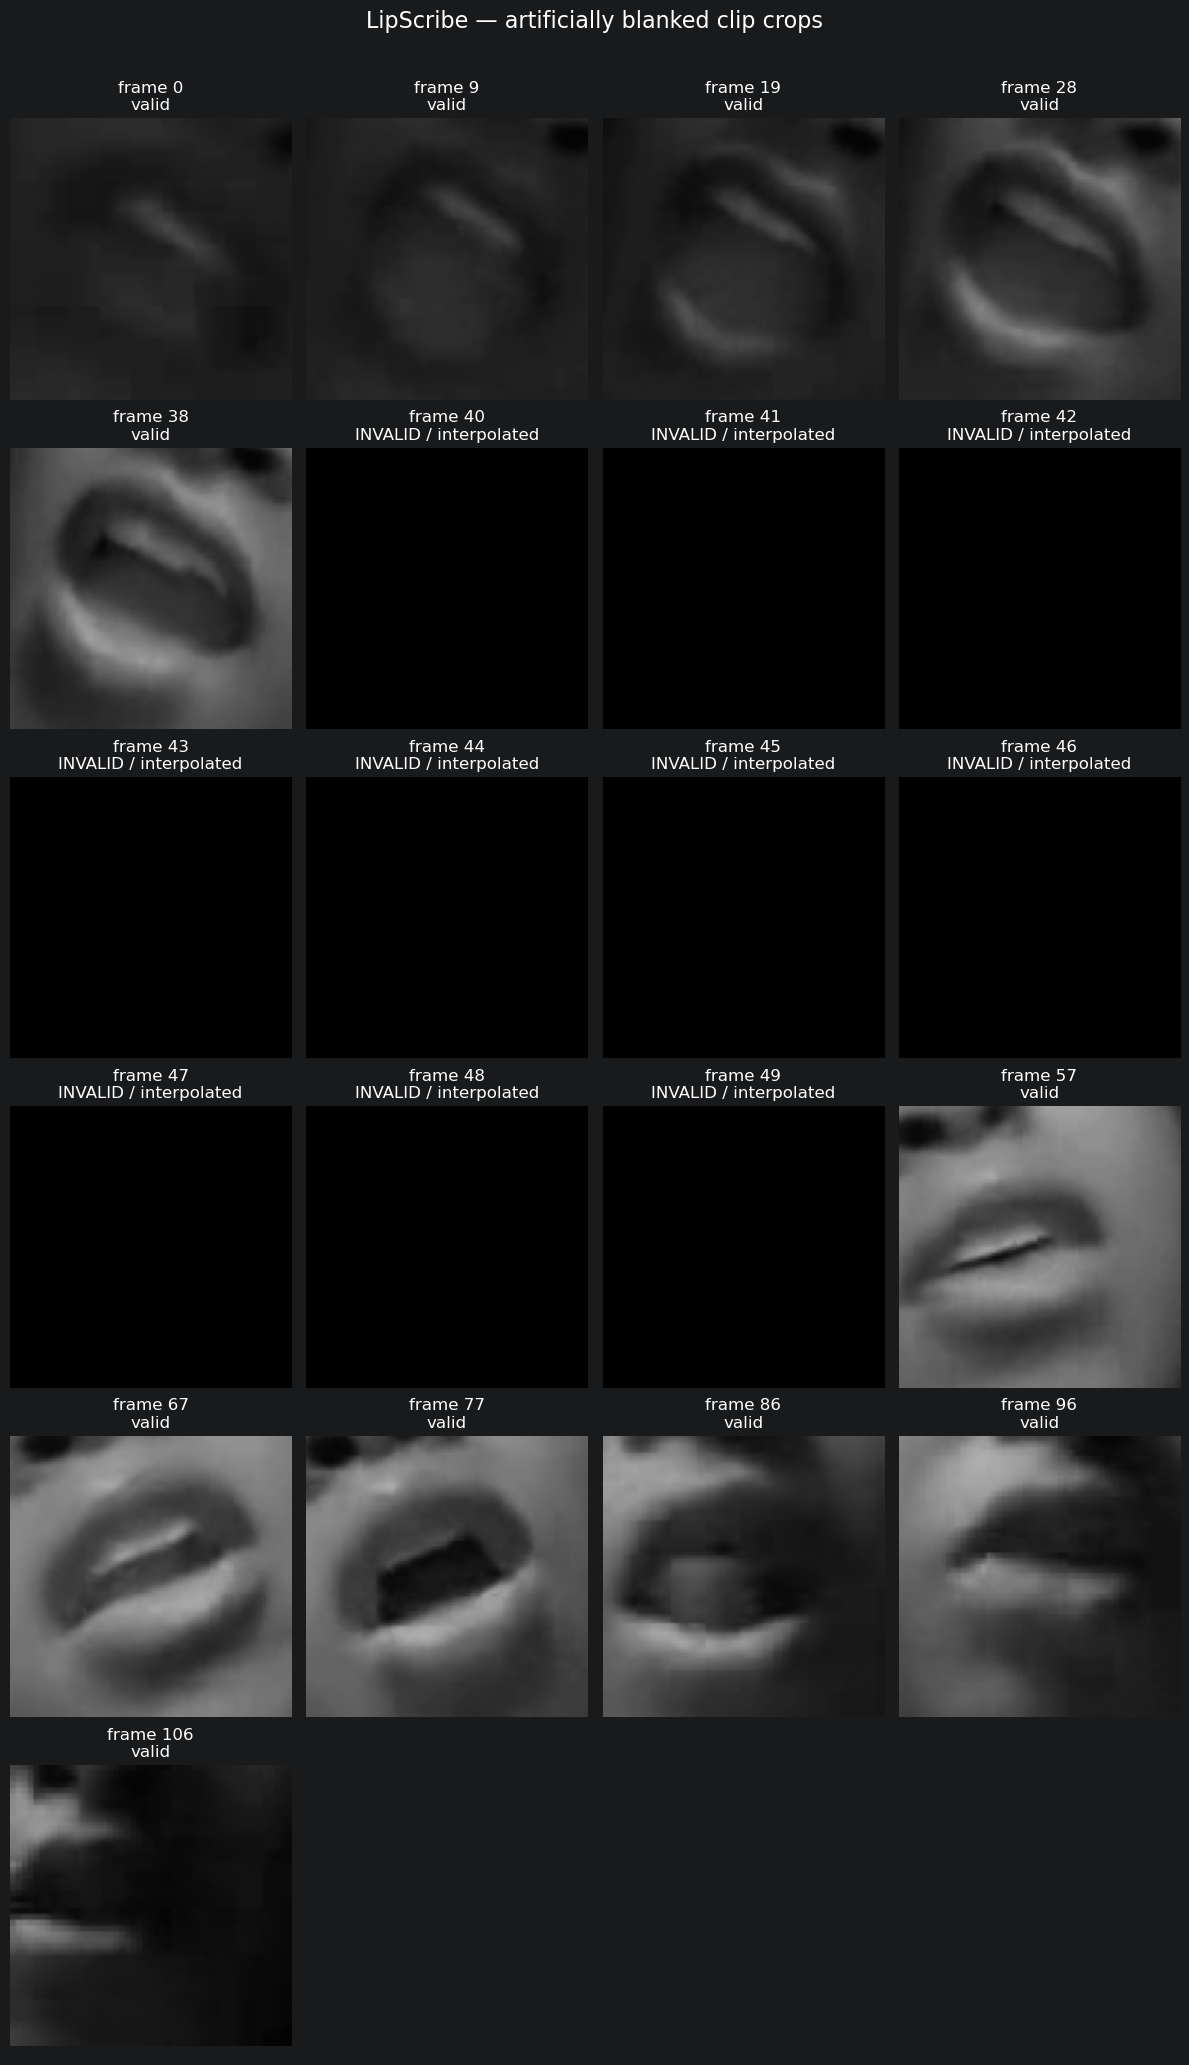

Saved: ../docs/mouth_crop/clip_6_blank_validation.png


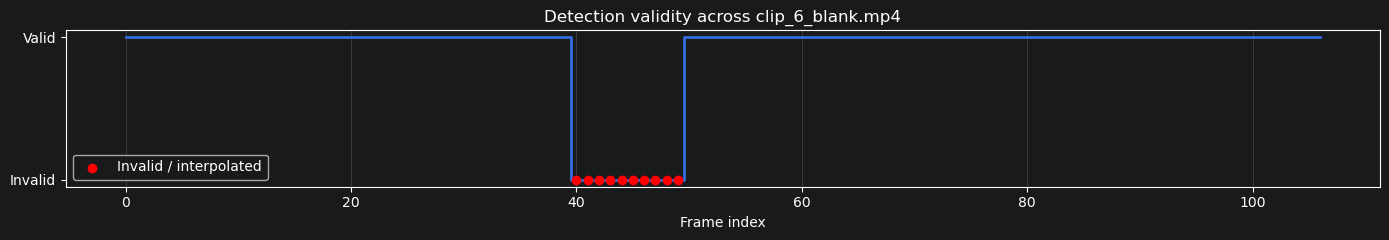

Saved: ../docs/mouth_crop/clip_6_blank_validity.png


In [8]:
# End-to-end validation on the artificially blanked clip.
if not BLANKED_CLIP.exists():
    print("No clip_6_blank.mp4 found; add it to data/mouth_crop_clips to run this cell.")
else:
    blanked_result = crop_video(
        video_path=BLANKED_CLIP,
        model_path=FACE_LANDMARKER_MODEL,
    )

    invalid_indices = np.flatnonzero(~blanked_result.valid)
    valid_indices = np.flatnonzero(blanked_result.valid)

    print("Clip:", BLANKED_CLIP.name)
    print("Crops:", blanked_result.crops.shape, blanked_result.crops.dtype)
    print("Valid frames:", len(valid_indices), "/", len(blanked_result.valid))
    print("Invalid frame indices:", invalid_indices.tolist())
    print("Invalid fraction:", blanked_result.invalid_fraction)
    print("Exclude utterance:", blanked_result.exclude_utterance)

    assert blanked_result.crops.shape[1:] == (96, 96)
    assert blanked_result.crops.dtype == np.uint8
    assert len(invalid_indices) > 0, "No invalid frames detected in blanked clip"
    assert len(valid_indices) > 0, "The clip must contain successful frames for interpolation"
    assert blanked_result.boxes is not None
    assert np.isfinite(blanked_result.boxes[invalid_indices]).all()
    assert np.all(blanked_result.boxes[invalid_indices, 2] > 0)

    # Include regular samples and every invalid frame in the visual evidence.
    regular = np.linspace(0, len(blanked_result.crops) - 1, min(12, len(blanked_result.crops)), dtype=int)
    display_indices = sorted(set(regular.tolist()) | set(invalid_indices.tolist()))
    columns = 4
    rows = int(np.ceil(len(display_indices) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(12, 3.4 * rows))
    axes = np.atleast_1d(axes).ravel()

    for axis, frame_index in zip(axes, display_indices):
        axis.imshow(blanked_result.crops[frame_index], cmap="gray", vmin=0, vmax=255)
        is_valid = bool(blanked_result.valid[frame_index])
        axis.set_title(f"frame {frame_index}\n{'valid' if is_valid else 'INVALID / interpolated'}")
        axis.axis("off")
        if not is_valid:
            for spine in axis.spines.values():
                spine.set_visible(True)
                spine.set_color("red")
                spine.set_linewidth(4)

    for axis in axes[len(display_indices):]:
        axis.axis("off")

    fig.suptitle("LipScribe — artificially blanked clip crops", fontsize=16, y=1.01)
    plt.tight_layout()
    blanked_sheet_path = ARTIFACT_DIR / "clip_6_blank_validation.png"
    fig.savefig(blanked_sheet_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", blanked_sheet_path)

    # Complete validity timeline.
    fig, axis = plt.subplots(figsize=(14, 2.5))
    axis.step(
        blanked_result.frame_indices,
        blanked_result.valid.astype(np.int8),
        where="mid",
        linewidth=2,
    )
    axis.scatter(
        invalid_indices,
        np.zeros(len(invalid_indices)),
        color="red",
        label="Invalid / interpolated",
        zorder=3,
    )
    axis.set_yticks([0, 1])
    axis.set_yticklabels(["Invalid", "Valid"])
    axis.set_xlabel("Frame index")
    axis.set_title("Detection validity across clip_6_blank.mp4")
    axis.grid(axis="x", alpha=0.3)
    axis.legend()
    plt.tight_layout()
    mask_plot_path = ARTIFACT_DIR / "clip_6_blank_validity.png"
    fig.savefig(mask_plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", mask_plot_path)

In [9]:
# Save crop arrays and metadata for the five baseline clips.
import json

crop_summary = {}
for clip_path, clip_result in all_results.items():
    clip_name = Path(clip_path).stem
    crops_path = CROPS_DIR / f"{clip_name}_crops.npy"
    valid_path = CROPS_DIR / f"{clip_name}_valid.npy"
    indices_path = CROPS_DIR / f"{clip_name}_frame_indices.npy"

    np.save(crops_path, clip_result.crops)
    np.save(valid_path, clip_result.valid)
    np.save(indices_path, clip_result.frame_indices)

    crop_summary[clip_name] = {
        "video": str(Path("../data/mouth_crop_clips") / f"{clip_name}.mp4"),
        "num_frames": int(len(clip_result.crops)),
        "valid_frames": int(clip_result.valid.sum()),
        "invalid_frames": int((~clip_result.valid).sum()),
        "invalid_fraction": clip_result.invalid_fraction,
        "exclude_utterance": bool(clip_result.exclude_utterance),
        "crop_shape": list(clip_result.crops.shape),
        "crop_dtype": str(clip_result.crops.dtype),
        "crops_file": str(crops_path),
        "valid_file": str(valid_path),
        "frame_indices_file": str(indices_path),
    }

summary_path = METADATA_DIR / "crop_summary_v002.json"
summary_path.write_text(json.dumps(crop_summary, indent=2), encoding="utf-8")
print("Saved crop arrays and metadata.")
print("Summary:", summary_path)

Saved crop arrays and metadata.
Summary: mouth_crop_results_metadata/crop_summary_v002.json


In [10]:
# Optional: run the crop and import tests from the notebook.
import subprocess

test_command = [
    sys.executable,
    "-m",
    "pytest",
    "-q",
    "tests/test_crop.py",
    "tests/test_import.py",
]
print("Running:", " ".join(test_command))
completed = subprocess.run(test_command, cwd=PROJECT_ROOT, check=False)
if completed.returncode != 0:
    raise RuntimeError(f"Tests failed with exit code {completed.returncode}")

Running: /home/kingcole/Documents/uniAssignments/year_3_sem_1/cv_group_4/.venv/bin/python -m pytest -q tests/test_crop.py tests/test_import.py
...........                                                              [100%]
11 passed in 69.79s (0:01:09)
